In [ ]:
from pathlib import Path
import os

# notebooks live in ai/notebooks/; data paths are relative to ai/
os.chdir(Path("..").resolve())


# FFT spectrum EDA

Compare real vs each attack in the frequency domain:

- mean log-magnitude spectrum (visual)
- high-frequency energy ratio per image
- Kolmogorov–Smirnov and Cohen's d on that ratio

Uses `metadata/manifest.csv`. Sample and seed match the intensity EDA (500 pairs / attack, seed 42) so the two notebooks are comparable. Closes the data + EDA milestone together with `eda_intensity.ipynb`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from scipy import stats

SEED = 42
N_SAMPLE = 500
HF_RADIUS_FRAC = 0.35  # outer ring starts at this fraction of max radius
rng = np.random.default_rng(SEED)

manifest = pd.read_csv("metadata/manifest.csv")
attacks = ["gaussian_noise", "gamma", "copy_region", "lesion_insert", "jpeg"]
Path("eda").mkdir(exist_ok=True)
manifest.label.value_counts(), manifest.attack.value_counts()

(label
 fake    29880
 real     7200
 Name: count, dtype: int64,
 attack
 none              7200
 gaussian_noise    7200
 gamma             7200
 copy_region       7200
 lesion_insert     7200
 jpeg              1080
 Name: count, dtype: int64)

In [2]:
def load_gray(path):
    return np.asarray(Image.open(path).convert("L"), dtype=np.float32)


def sample_pairs(attack, n=N_SAMPLE):
    fake = manifest[(manifest.attack == attack) & (manifest.label == "fake")].copy()
    if len(fake) > n:
        fake = fake.sample(n=n, random_state=SEED)
    rows = []
    for _, row in fake.iterrows():
        rows.append({
            "attack": attack,
            "real_path": row.source_path,
            "fake_path": row.path,
            "held_out": bool(row.held_out),
        })
    return pd.DataFrame(rows)


def fft_log_mag(gray):
    # zero-mean before FFT so DC does not dominate every comparison
    x = gray - gray.mean()
    spec = np.fft.fftshift(np.fft.fft2(x))
    return np.log1p(np.abs(spec))


def radial_masks(h, w, hf_frac=HF_RADIUS_FRAC):
    cy, cx = h // 2, w // 2
    yy, xx = np.ogrid[:h, :w]
    r = np.sqrt((yy - cy) ** 2 + (xx - cx) ** 2)
    r_max = r.max()
    high = r >= (hf_frac * r_max)
    return high, r, r_max


def high_freq_ratio(gray):
    log_mag = fft_log_mag(gray)
    high_mask, _, _ = radial_masks(*gray.shape)
    mag = np.expm1(log_mag)
    power = mag ** 2
    total = power.sum() + 1e-12
    return float(power[high_mask].sum() / total), log_mag


pairs = pd.concat([sample_pairs(a) for a in attacks], ignore_index=True)
pairs.groupby("attack").size()

attack
copy_region       500
gamma             500
gaussian_noise    500
jpeg              500
lesion_insert     500
dtype: int64

In [3]:
def cohens_d(a, b):
    a = np.asarray(a, dtype=np.float64)
    b = np.asarray(b, dtype=np.float64)
    na, nb = len(a), len(b)
    va, vb = a.var(ddof=1), b.var(ddof=1)
    pooled = np.sqrt(((na - 1) * va + (nb - 1) * vb) / (na + nb - 2))
    if pooled == 0:
        return 0.0
    return float((a.mean() - b.mean()) / pooled)


stats_rows = []
hf_values = {}
mean_spectra = {}  # attack -> (real_mean_logmag, fake_mean_logmag)
TARGET = 256  # resize so stacked mean spectra share one shape


def prep(gray):
    img = Image.fromarray(gray.astype(np.uint8)).resize((TARGET, TARGET), Image.BILINEAR)
    return np.asarray(img, dtype=np.float32)


for attack in attacks:
    sub = pairs[pairs.attack == attack]
    real_hf, fake_hf = [], []
    real_stack, fake_stack = [], []

    for _, row in sub.iterrows():
        real_gray = prep(load_gray(row.real_path))
        fake_gray = prep(load_gray(row.fake_path))
        rh, r_spec = high_freq_ratio(real_gray)
        fh, f_spec = high_freq_ratio(fake_gray)
        real_hf.append(rh)
        fake_hf.append(fh)
        real_stack.append(r_spec)
        fake_stack.append(f_spec)

    real_hf = np.asarray(real_hf, dtype=np.float64)
    fake_hf = np.asarray(fake_hf, dtype=np.float64)
    hf_values[attack] = (real_hf, fake_hf)
    mean_spectra[attack] = (
        np.mean(real_stack, axis=0),
        np.mean(fake_stack, axis=0),
    )

    ks = stats.ks_2samp(real_hf, fake_hf)
    d = cohens_d(real_hf, fake_hf)
    stats_rows.append({
        "attack": attack,
        "n": len(sub),
        "feature": "high_freq_energy_ratio",
        "hf_radius_frac": HF_RADIUS_FRAC,
        "real_mean": float(real_hf.mean()),
        "fake_mean": float(fake_hf.mean()),
        "real_std": float(real_hf.std(ddof=1)),
        "fake_std": float(fake_hf.std(ddof=1)),
        "ks_stat": float(ks.statistic),
        "ks_pvalue": float(ks.pvalue),
        "cohens_d": d,
        "held_out": bool(sub.held_out.iloc[0]),
    })
    print(
        attack,
        "KS", round(ks.statistic, 4),
        "p", f"{ks.pvalue:.2e}",
        "d", round(d, 3),
        "real_hf", round(real_hf.mean(), 4),
        "fake_hf", round(fake_hf.mean(), 4),
    )

fft_stats = pd.DataFrame(stats_rows)
fft_stats.to_csv("eda/fft_stats.csv", index=False)
fft_stats

gaussian_noise KS 0.456 p 3.07e-47 d -0.524 real_hf 0.0106 fake_hf 0.0181


gamma KS 0.192 p 1.80e-08 d -0.188 real_hf 0.0106 fake_hf 0.0133


copy_region KS 0.018 p 1.00e+00 d -0.002 real_hf 0.0106 fake_hf 0.0106


lesion_insert KS 0.018 p 1.00e+00 d 0.005 real_hf 0.0106 fake_hf 0.0106


jpeg KS 0.038 p 8.64e-01 d 0.032 real_hf 0.0114 fake_hf 0.011


,attack,n,feature,hf_radius_frac,real_mean,fake_mean,real_std,fake_std,ks_stat,ks_pvalue,cohens_d,held_out
0,gaussian_noise,500,high_freq_energy_ratio,0.35,0.010617,0.018131,0.013070,0.015482,0.456,3.070649e-47,-0.524424,False
1,gamma,500,high_freq_energy_ratio,0.35,0.010617,0.013324,0.013070,0.015616,0.192,1.796150e-08,-0.188006,False
2,copy_region,500,high_freq_energy_ratio,0.35,0.010617,0.010646,0.013070,0.013038,0.018,9.999980e-01,-0.002214,False
3,lesion_insert,500,high_freq_energy_ratio,0.35,0.010617,0.010555,0.013070,0.012879,0.018,9.999980e-01,0.004776,False
4,jpeg,500,high_freq_energy_ratio,0.35,0.011407,0.010962,0.014273,0.013185,0.038,8.636767e-01,0.032337,True


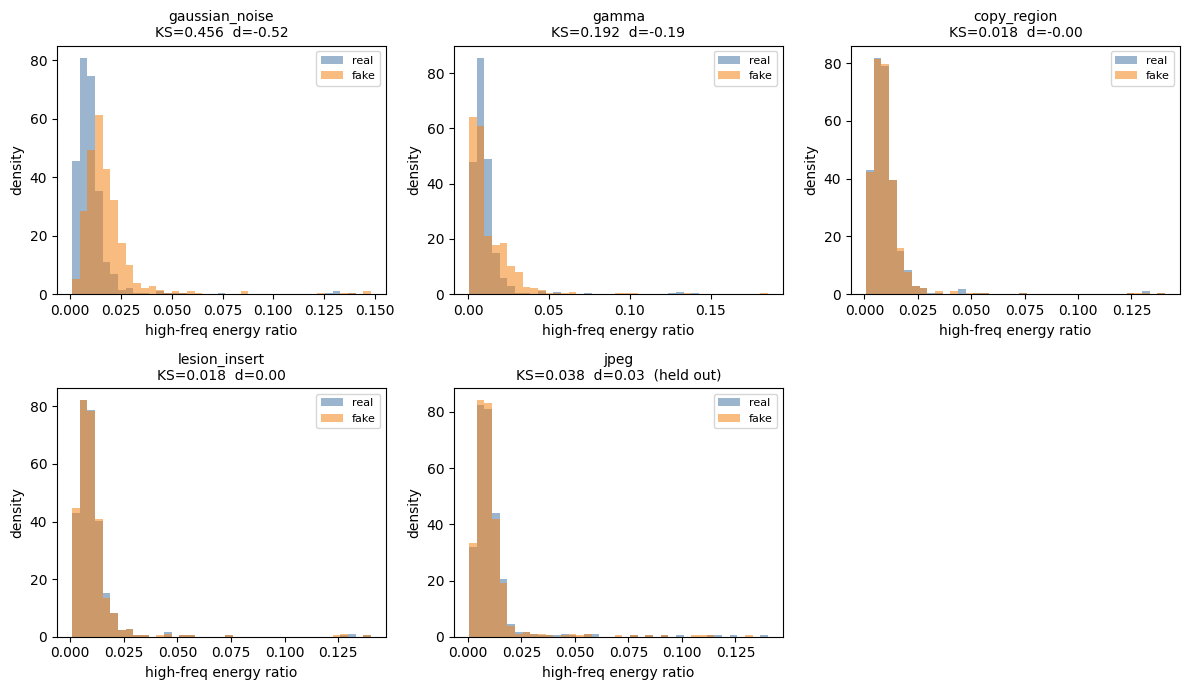

In [4]:
# histograms of high-frequency energy ratio
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
axes = axes.ravel()

for i, attack in enumerate(attacks):
    real_hf, fake_hf = hf_values[attack]
    ax = axes[i]
    lo = min(real_hf.min(), fake_hf.min())
    hi = max(real_hf.max(), fake_hf.max())
    bins = np.linspace(lo, hi, 40)
    ax.hist(real_hf, bins=bins, alpha=0.55, label="real", color="#4c78a8", density=True)
    ax.hist(fake_hf, bins=bins, alpha=0.55, label="fake", color="#f58518", density=True)
    row = fft_stats[fft_stats.attack == attack].iloc[0]
    title = f"{attack}\nKS={row.ks_stat:.3f}  d={row.cohens_d:.2f}"
    if row.held_out:
        title += "  (held out)"
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("high-freq energy ratio")
    ax.set_ylabel("density")
    ax.legend(fontsize=8)

axes[-1].axis("off")
plt.tight_layout()
plt.savefig("eda/fft_hf_ratio_histograms.png", dpi=140, bbox_inches="tight")
plt.show()

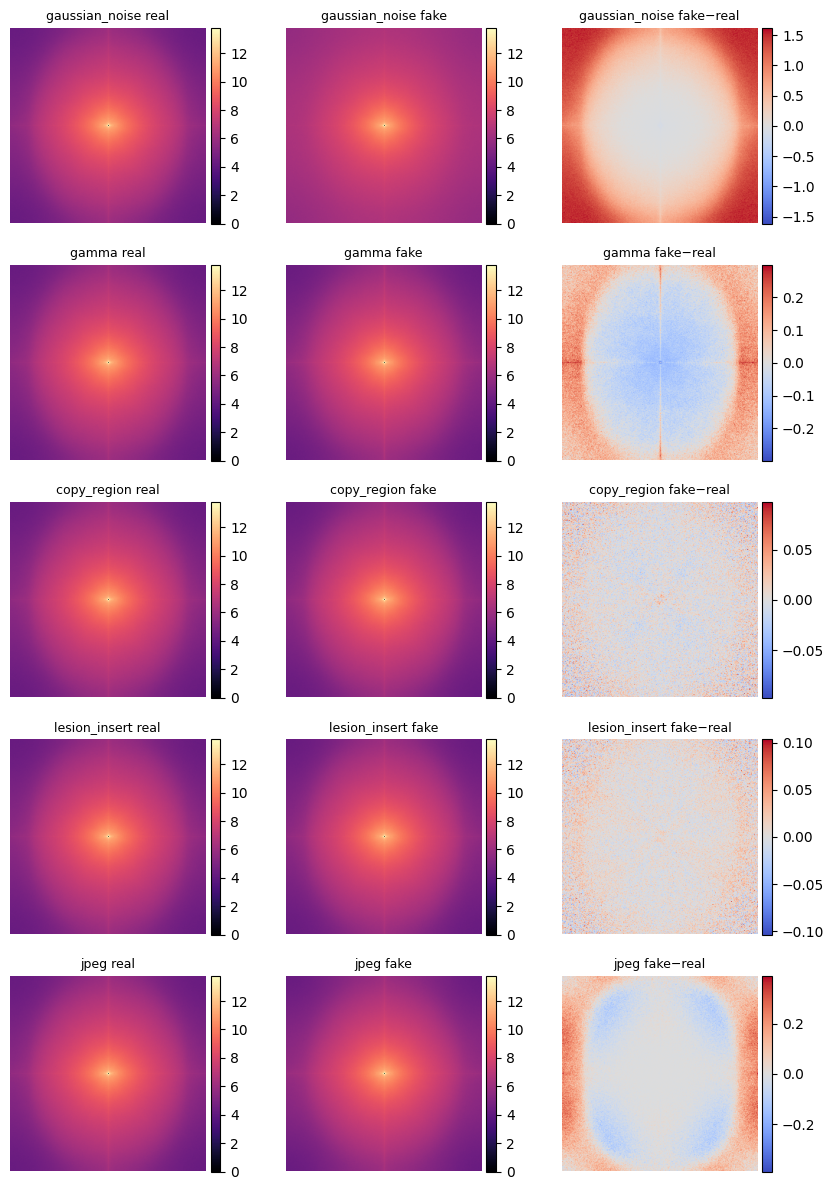

In [5]:
# mean log-magnitude spectra: real | fake | |fake - real|
fig, axes = plt.subplots(len(attacks), 3, figsize=(9, 2.4 * len(attacks)))

for r, attack in enumerate(attacks):
    real_m, fake_m = mean_spectra[attack]
    diff = fake_m - real_m
    panels = [real_m, fake_m, diff]
    titles = [f"{attack} real", f"{attack} fake", f"{attack} fake−real"]
    # shared scale for real/fake; separate for diff
    vmin = min(real_m.min(), fake_m.min())
    vmax = max(real_m.max(), fake_m.max())
    dlim = np.max(np.abs(diff))
    for c, (img, title) in enumerate(zip(panels, titles)):
        ax = axes[r, c]
        if c < 2:
            im = ax.imshow(img, cmap="magma", vmin=vmin, vmax=vmax)
        else:
            im = ax.imshow(img, cmap="coolwarm", vmin=-dlim, vmax=dlim)
        ax.set_title(title, fontsize=9)
        ax.axis("off")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)

plt.tight_layout()
plt.savefig("eda/fft_mean_spectra.png", dpi=120, bbox_inches="tight")
plt.show()

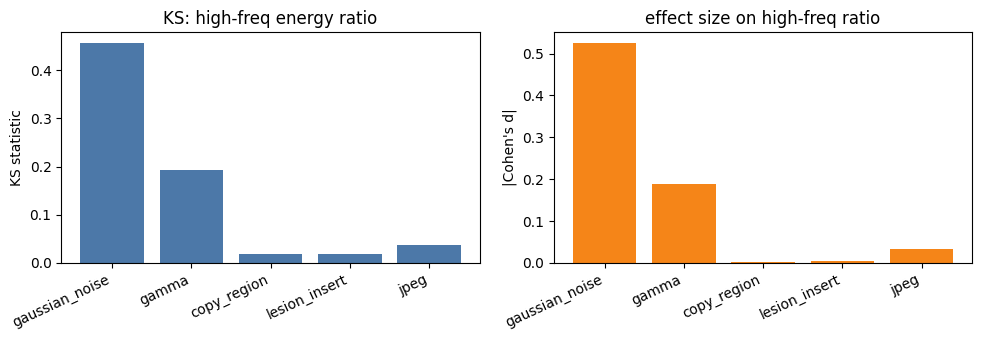

FFT vs intensity (same sample protocol)
        attack  intensity_ks  fft_ks  intensity_d     fft_d
gaussian_noise         0.122   0.456    -0.147261 -0.524424
         gamma         0.316   0.192    -0.233035 -0.188006
   copy_region         0.016   0.018    -0.002861 -0.002214
 lesion_insert         0.024   0.018    -0.012328  0.004776
          jpeg         0.020   0.038    -0.011588  0.032337
saved eda_fft_stats.csv and plots under eda/


,attack,ks_stat,ks_pvalue,cohens_d,held_out
0,gaussian_noise,0.456,3.070649e-47,-0.524424,False
1,gamma,0.192,1.796150e-08,-0.188006,False
2,copy_region,0.018,9.999980e-01,-0.002214,False
3,lesion_insert,0.018,9.999980e-01,0.004776,False
4,jpeg,0.038,8.636767e-01,0.032337,True


In [6]:
# bar chart: KS and |Cohen's d| on high-freq ratio
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

x = np.arange(len(fft_stats))
labels = fft_stats.attack.tolist()

axes[0].bar(x, fft_stats.ks_stat, color="#4c78a8")
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels, rotation=25, ha="right")
axes[0].set_ylabel("KS statistic")
axes[0].set_title("KS: high-freq energy ratio")

axes[1].bar(x, fft_stats.cohens_d.abs(), color="#f58518")
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels, rotation=25, ha="right")
axes[1].set_ylabel("|Cohen's d|")
axes[1].set_title("effect size on high-freq ratio")

plt.tight_layout()
plt.savefig("eda/fft_ks_cohens_d.png", dpi=140, bbox_inches="tight")
plt.show()

# side-by-side with intensity EDA if available
intensity_path = Path("eda/intensity_stats.csv")
if intensity_path.exists():
    inten = pd.read_csv(intensity_path)
    merged = fft_stats[["attack", "ks_stat", "cohens_d"]].rename(
        columns={"ks_stat": "fft_ks", "cohens_d": "fft_d"}
    ).merge(
        inten[["attack", "ks_stat", "cohens_d"]].rename(
            columns={"ks_stat": "intensity_ks", "cohens_d": "intensity_d"}
        ),
        on="attack",
    )
    print("FFT vs intensity (same sample protocol)")
    display_cols = ["attack", "intensity_ks", "fft_ks", "intensity_d", "fft_d"]
    print(merged[display_cols].to_string(index=False))
else:
    merged = None

print("saved eda/fft_stats.csv and plots under eda/")
fft_stats[["attack", "ks_stat", "ks_pvalue", "cohens_d", "held_out"]]

## Documentation: FFT Spectrum EDA — Findings, Limits, and Next Steps

This note interprets the frequency-domain EDA only. Quantitative claims refer to **500 paired images per attack** (seed 42), images resized to **256×256** for a common FFT grid, and the scalar feature **high-frequency energy ratio** (power outside 35% of the maximum radius in the shifted spectrum, after subtracting the spatial mean). Spectra plots average log-magnitude over the same pairs. Numbers are in `eda/fft_stats.csv`; figures are under `eda/`.

### What we measured

| Attack | Real HF mean | Fake HF mean | KS | *p* | Cohen’s *d* | Held out |
|--------|--------------|--------------|-----|-----|-------------|----------|
| gaussian_noise | 0.0106 | 0.0181 | **0.456** | ~0 | **−0.524** | no |
| gamma | 0.0106 | 0.0133 | 0.192 | 1.8×10⁻⁸ | −0.188 | no |
| copy_region | 0.0106 | 0.0106 | 0.018 | ~1 | −0.002 | no |
| lesion_insert | 0.0106 | 0.0106 | 0.018 | ~1 | +0.005 | no |
| jpeg | 0.0114 | 0.0110 | 0.038 | 0.86 | +0.032 | **yes** |

*(Negative *d* = fake has higher HF ratio than real on average.)*

### Comparison with intensity EDA (same protocol)

| Attack | Intensity KS | FFT KS | Intensity \|*d*\| | FFT \|*d*\| |
|--------|--------------|--------|-------------------|-------------|
| gaussian_noise | 0.122 | **0.456** | 0.15 | **0.52** |
| gamma | **0.316** | 0.192 | **0.23** | 0.19 |
| copy_region | ~0.02 | ~0.02 | ~0 | ~0 |
| lesion_insert | ~0.02 | ~0.02 | ~0 | ~0 |
| jpeg | ~0.02 | ~0.04 | ~0.01 | ~0.03 |

### Interpretation

**1. FFT and intensity are complementary for photometric attacks.**

- **Gaussian noise** is much clearer in the high-frequency ratio than in mean intensity (KS 0.46 vs 0.12; |*d*| 0.52 vs 0.15). That matches the physics of additive noise injecting energy into high frequencies. Histograms show a clear rightward shift for fakes.
- **Gamma** remains significant in FFT but weaker than in intensity (KS 0.19 vs 0.32). Brightness remapping changes global intensity strongly; its effect on this particular HF-ratio summary is real but smaller. Intensity remains the stronger *simple* cue for gamma under our two scalars.

**2. Global FFT still does not expose copy-region or lesion-insert.**

KS ≈ 0.018 and *p* ≈ 1: we have no evidence that the **image-wide** HF energy ratio differs for these attacks. Localized splicing can leave the bulk spectrum almost unchanged. This does **not** prove the forgeries are undetectable; it proves this **global frequency scalar** is the wrong tool for them.

**3. JPEG (held out) is not separated by this HF ratio either.**

KS 0.038 with *p* ≈ 0.86 is a null result under this feature and resize. That is important: we must **not** claim FFT “catches compression” from these numbers. Possible reasons include mild quality setting relative to MRI content, and **resizing to 256×256**, which can smear block artifacts before the FFT. Stronger JPEG-oriented features (e.g. blockiness, DCT coefficient stats) were not tested here.

**4. What this does *not* prove**

- That a classifier using raw FFT maps (or a CNN) will fail on copy/lesion — only that **one global HF ratio** fails.
- That noise is “solved” by FFT alone — |*d*| ≈ 0.5 is a medium effect with remaining overlap.
- That milestone-1 EDA is a substitute for training metrics (Precision/Recall/F1, ROC-AUC per attack).

### Limitations

1. Single scalar (HF energy ratio) + mean log-magnitude visuals; no radial profile KS, no local/patch FFT.
2. Fixed HF threshold (35% of max radius) was chosen a priori, not tuned.
3. Resize to 256×256 changes the spectrum relative to native resolution (needed because source sizes vary, e.g. 512 vs ~630).
4. Sample of 500 / attack; exploratory *p*-values without multiplicity correction.
5. JPEG pool differs (test-only), as in the intensity notebook.

### Decisions for the project (closing the data + EDA milestone)

Together with `eda_intensity.ipynb`, the evidence supports:

1. **Keep Histogram (intensity) and FFT features as research baselines** for Day 15 — not as the product detector. Intensity is more informative for gamma; FFT HF ratio is more informative for noise; **neither** covers copy/lesion/JPEG under these tests.
2. **Do not drop structural attacks.** Their EDA-null status is exactly why a spatial learner (ResNet18) is required next.
3. **Treat JPEG only as held-out evaluation**, and do not expect the current FFT scalar to explain JPEG robustness.
4. **Next engineering step (plan Day 14+):** freeze `metadata/manifest.csv` / splits, smoke-test one ResNet18 epoch, then full training and attack-wise metrics. Optional later work (local/patch spectra, noise residuals) can enrich baselines but should not delay the model freeze date.

### Milestone status

**Data + EDA milestone is complete for the planned scope:** real/fake corpus with `metadata/manifest.csv`, intensity EDA (histogram, KS, Cohen’s *d*), and FFT spectrum EDA with comparable protocol and documented limits. The next stage is model training and measured detection performance — not more global EDA alone.